# Set 8 — Image classification with CNNs: model passport, transfer learning and feature projection

Based on the lab notebook *image_classification_using_cnn.ipynb* (CIFAR-10 with Keras). This notebook covers the three parts of Set 8:

* **8.1 Train a classification model**: train CNNs, save the weights and the **model passport** (dataset and sample sizes, class names, preprocessing instructions, training history).
* **8.2 Load a pretrained model and use it**: load a model, display its passport, classify images and see with **Grad-CAM** where the network looked.
* **8.3 Feature projection**: extract the feature vectors of the test set, save them, load them and project them onto 2-D with **t-SNE** and **UMAP**.

Three models are trained: the small CNN and the deeper VGG-style CNN from the lab, and an InceptionV3 pre-trained on ImageNet (transfer learning).

**Output, used by ForensicsApp.** Every model is saved in its own folder, and the last cell zips them as `cnn_models.zip`:

```
cnn_models/<model name>/
    model.keras          architecture + trained weights
    passport.json        the model passport
    test_features.npz    feature vectors of the test set (8.3)
    test_samples/        10 test images per class, named <index>_<class>.png
```

Unzip it into `ForensicsApp/models/cnn/` (so you get `models/cnn/small_cnn/passport.json`, ...). The app tools *CNN: Classify Image (Set 8.2)* and *CNN: Feature Projection (Set 8.3)* read these folders. To load the models the app needs `pip install -r requirements-keras.txt`.

**Runtime.** Use a GPU: *Runtime → Change runtime type → GPU*. With a T4 the whole notebook takes about 20–25 minutes.

In [1]:
import json
import shutil
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt
from PIL import Image
import tensorflow as tf
import keras
from keras import layers
from keras.utils import to_categorical
from sklearn.metrics import confusion_matrix

keras.utils.set_random_seed(0)  # same initial weights and data order on every run

OUTPUT_DIR = Path("cnn_models")  # one sub-folder per trained model, zipped at the end
PASSPORT_VERSION = 1  # the app checks this number before reading a passport
SAMPLES_PER_CLASS = 10  # test images saved next to every model, so the app can classify images of known class

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (Runtime > Change runtime type > GPU)")

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## The dataset: CIFAR-10

CIFAR-10 has 60000 colour images of 32 × 32 pixels in 10 classes, 6000 per class: 50000 for training and 10000 for testing ([more information](https://www.cs.toronto.edu/~kriz/cifar.html)). Keras loads it as NumPy arrays; labels are class indexes from 0 to 9.

We keep the original `uint8` images: every model applies its own preprocessing, written in its passport.

In [2]:
from keras.datasets import cifar10

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

(x_train, y_train), (x_test, y_test) = cifar10.load_data()
y_train, y_test = y_train.ravel(), y_test.ravel()  # (n, 1) -> (n,) class indexes

print("train:", x_train.shape, x_train.dtype, "| test:", x_test.shape)
print("training images per class:", np.bincount(y_train))

# One-hot labels for the categorical cross-entropy loss
y_train_onehot = to_categorical(y_train, num_classes=len(CLASS_NAMES))
y_test_onehot = to_categorical(y_test, num_classes=len(CLASS_NAMES))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 108s 1us/step
train: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3)
training images per class: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


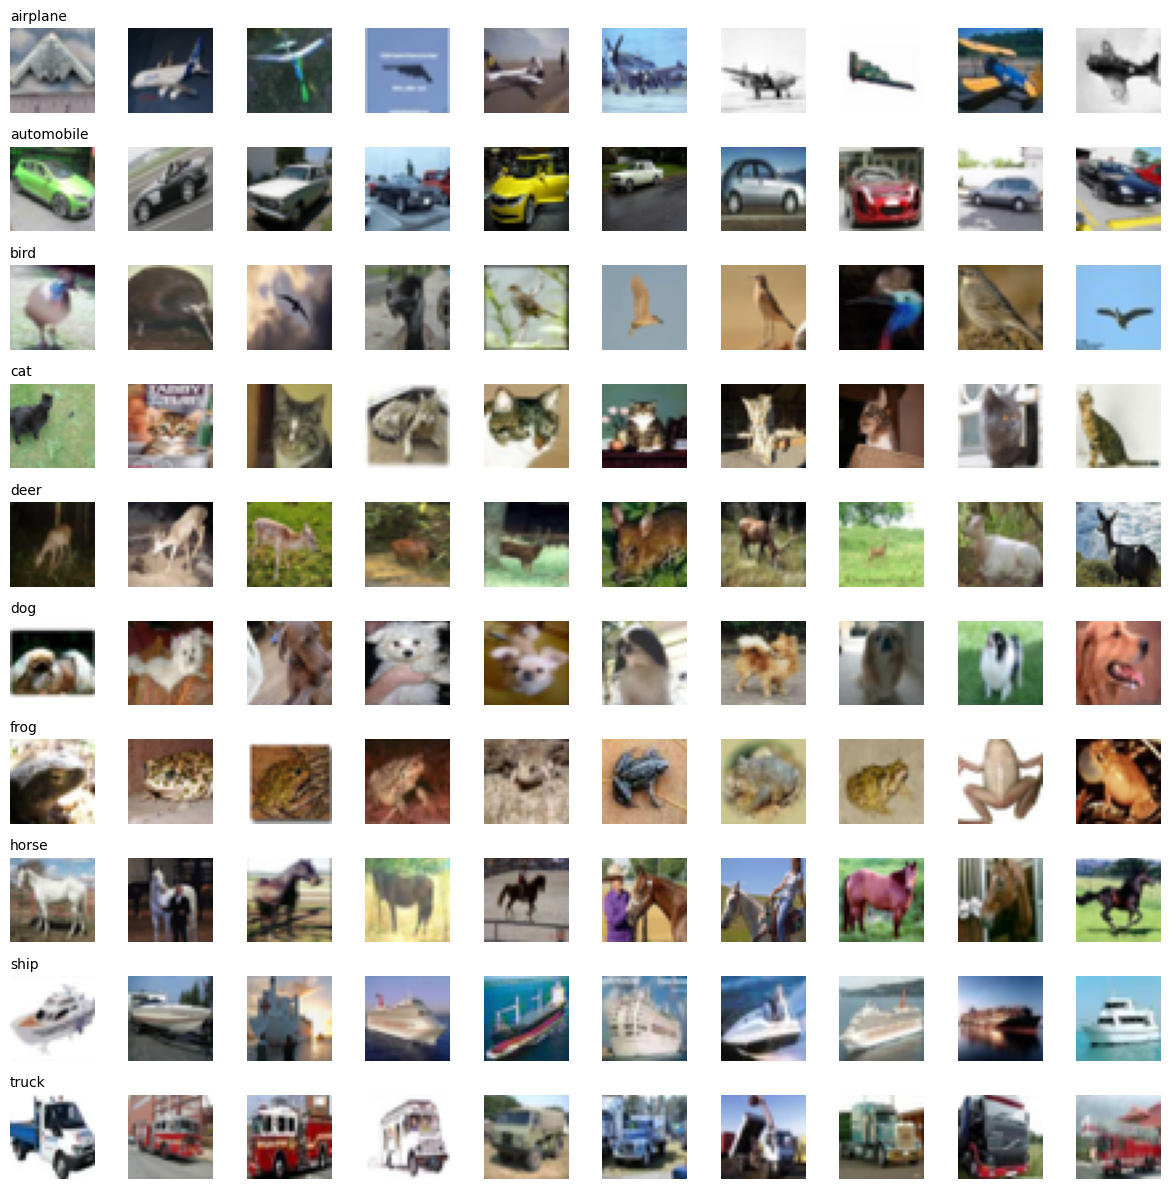

In [3]:
# 10 x 10 grid: one row per class, 10 random training images of that class
rng = np.random.default_rng(0)
fig, axes = plt.subplots(10, 10, figsize=(12, 12))
for row, name in enumerate(CLASS_NAMES):
    picks = rng.choice(np.flatnonzero(y_train == row), 10, replace=False)
    for col, index in enumerate(picks):
        axes[row, col].imshow(x_train[index])
        axes[row, col].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## Preprocessing instructions

The passport stores how an image must be prepared before it enters the network, so the model can be used outside this notebook:

* `input_size`: `[height, width]` of the network input;
* `resize_mode: "center_crop"`: cut the largest centred region with the input's shape (a square here), then resize it with bilinear interpolation. A 640 × 480 photo keeps its proportions instead of being squashed;
* every pixel value `v` (0–255) becomes `v * scale + offset`.

`prepare_image` applies these steps to any image. The app implements exactly the same steps (`forensics_app/tools/cnn_model.py`), so keep both in sync. CIFAR-10 images already have the input size, so for the dataset arrays only the scaling is needed (`prepare_batch`).

In [4]:
def make_preprocessing(scale, offset, description, input_size=(32, 32)):
    # The preprocessing section of the passport (read by the app)
    return {
        "input_size": list(input_size),  # [height, width] of the network input
        "color_mode": "rgb",
        "resize_mode": "center_crop",  # largest centred region with the input shape, then resize
        "interpolation": "bilinear",
        "scale": scale,  # pixel value (0..255) * scale + offset
        "offset": offset,
        "description": description,
    }


def prepare_batch(images, preprocessing):
    # CIFAR-10 arrays (n, 32, 32, 3) uint8 -> network input; they already have the input size
    assert list(images.shape[1:3]) == preprocessing["input_size"], "these images must be resized first"
    return images.astype("float32") * preprocessing["scale"] + preprocessing["offset"]


def prepare_image(image, preprocessing):
    # Any PIL image -> (1, height, width, 3) network input: the same steps as the app
    height, width = preprocessing["input_size"]
    rgb = image.convert("RGB")
    aspect = width / height
    crop_width = min(rgb.width, rgb.height * aspect)
    crop_height = crop_width / aspect
    left = round((rgb.width - crop_width) / 2)
    top = round((rgb.height - crop_height) / 2)
    box = (left, top, min(rgb.width, left + max(1, round(crop_width))), min(rgb.height, top + max(1, round(crop_height))))
    patch = rgb.crop(box).resize((width, height), Image.Resampling.BILINEAR)
    pixels = np.asarray(patch, dtype="float32") * preprocessing["scale"] + preprocessing["offset"]
    return pixels[np.newaxis]

## 8.1 Saving a model with its passport

`save_model_with_passport` saves the trained weights (`model.keras`, which also stores the architecture) and the passport (`passport.json`) with:

* **dataset and sample sizes**: name, source, train / validation / test images;
* **class names**: the meaning of every output of the network, in order;
* **preprocessing instructions** (above);
* **training**: optimizer, loss, epochs, batch size, time, and the **history** (loss and accuracy per epoch, train and validation);
* **evaluation** on the test set: loss, accuracy and confusion matrix.

Every model names a few layers so the app can find them:

* `features`: the last hidden layer, whose output is the feature vector used in 8.3;
* `logits`: the class scores before the softmax (`predictions` applies the softmax), used by Grad-CAM;
* the passport's `gradcam_layer` (`last_conv` for the CNNs trained from scratch): the last layer with feature maps, also for Grad-CAM.

In [5]:
def save_test_samples(folder, per_class=SAMPLES_PER_CLASS):
    # A few test images as <index>_<class>.png: the app can classify them and knows the true class
    folder.mkdir(parents=True, exist_ok=True)
    for label, name in enumerate(CLASS_NAMES):
        for index in np.flatnonzero(y_test == label)[:per_class]:
            Image.fromarray(x_test[index]).save(folder / f"{index:05d}_{name}.png")


def merge_histories(*histories):
    # One history from several model.fit calls (transfer learning trains in two phases)
    merged = {}
    for history in histories:
        for key, values in history.history.items():
            merged.setdefault(key, []).extend(float(value) for value in values)
    return merged


def save_model_with_passport(model, name, title, description, architecture, gradcam_layer, preprocessing,
                             training, histories, train_samples, validation_samples):
    # Set 8.1: save the trained weights (model.keras) and the model passport (passport.json)
    folder = OUTPUT_DIR / name
    if folder.exists():
        shutil.rmtree(folder)
    folder.mkdir(parents=True)
    model.save(folder / "model.keras")

    x_test_input = prepare_batch(x_test, preprocessing)
    test_loss, test_accuracy = model.evaluate(x_test_input, y_test_onehot, batch_size=256, verbose=0)
    predicted = model.predict(x_test_input, batch_size=256, verbose=0).argmax(axis=1)
    passport = {
        "format_version": PASSPORT_VERSION,
        "name": name,
        "title": title,
        "description": description,
        "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "framework": {"Keras": keras.__version__, "TensorFlow": tf.__version__},
        "files": {"model": "model.keras", "test_features": "test_features.npz", "test_samples": "test_samples"},
        "architecture": {
            "summary": architecture,
            "parameters": int(model.count_params()),
            "feature_layer": "features",
            "feature_size": int(model.get_layer("features").units),
            "gradcam_layer": gradcam_layer,  # last layer with feature maps, for Grad-CAM
        },
        "dataset": {
            "name": "CIFAR-10",
            "source": "keras.datasets.cifar10 (https://www.cs.toronto.edu/~kriz/cifar.html)",
            "image_size": [32, 32],
            "train_samples": int(train_samples),
            "validation_samples": int(validation_samples),
            "test_samples": int(len(y_test)),
        },
        "class_names": CLASS_NAMES,
        "preprocessing": preprocessing,
        "training": training,
        "history": merge_histories(*histories),
        "evaluation": {
            "test_loss": float(test_loss),
            "test_accuracy": float(test_accuracy),
            "confusion_matrix": confusion_matrix(y_test, predicted, labels=range(len(CLASS_NAMES))).tolist(),
        },
    }
    (folder / "passport.json").write_text(json.dumps(passport, indent=2))
    save_test_samples(folder / "test_samples")
    print(f"Saved {folder}: test accuracy {test_accuracy:.1%}, test loss {test_loss:.3f}")
    return folder

### 8.1a A small CNN (from the lab)

A single convolutional layer with 32 filters of 3 × 3 and a max pooling layer; the filter maps are flattened and go to a dense layer of 100 units, then to the softmax classification layer. Trained with SGD and the categorical cross-entropy, batch size 32, keeping 10% of the training images for validation.

In [6]:
EPOCHS = 30  # the lab suggests 50 or more; 30 takes about 3 minutes per model on a Colab GPU
VALIDATION_SPLIT = 0.1  # Keras keeps the last 10% of the training images for validation
n_validation = int(len(x_train) * VALIDATION_SPLIT)

small_preprocessing = make_preprocessing(1 / 255, 0.0, "pixels scaled to [0, 1]")
x_train_small = prepare_batch(x_train, small_preprocessing)

keras.backend.clear_session()
small_model = keras.Sequential(
    [
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation="relu", kernel_initializer="he_uniform", name="last_conv"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(100, activation="relu", kernel_initializer="he_uniform", name="features"),
        layers.Dense(10, name="logits"),  # class scores before the softmax (used by Grad-CAM)
        layers.Activation("softmax", name="predictions"),
    ],
    name="small_cnn",
)
small_model.summary()

Model: "small_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ last_conv (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ features (Dense)                │ (None, 100)            │       720,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │         1,010 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Activation)        │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 722,006 (2.75 MB)

 Trainable params: 722,006 (2.75 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
small_model.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(learning_rate=0.01), metrics=["accuracy"])
start = time.perf_counter()
history_small = small_model.fit(x_train_small, y_train_onehot, epochs=EPOCHS, batch_size=32, validation_split=VALIDATION_SPLIT)
small_seconds = time.perf_counter() - start

save_model_with_passport(
    small_model,
    name="small_cnn",
    title="Small CNN (1 conv layer)",
    description="Set 8 lab baseline: one 3x3 convolutional layer, max pooling and a dense layer.",
    architecture="Conv2D 32 3x3 ReLU -> MaxPool 2x2 -> Flatten -> Dense 100 ReLU (features) -> Dense 10 (logits) -> softmax",
    gradcam_layer="last_conv",
    preprocessing=small_preprocessing,
    training={
        "optimizer": "SGD (learning rate 0.01)",
        "loss": "categorical_crossentropy",
        "epochs": EPOCHS,
        "batch_size": 32,
        "validation_split": VALIDATION_SPLIT,
        "seconds": round(small_seconds, 1),
    },
    histories=[history_small],
    train_samples=len(x_train) - n_validation,
    validation_samples=n_validation,
)

Epoch 1/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.3452 - loss: 1.8268 - val_accuracy: 0.3944 - val_loss: 1.6716
Epoch 2/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4637 - loss: 1.5128 - val_accuracy: 0.4854 - val_loss: 1.4625
Epoch 3/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5199 - loss: 1.3590 - val_accuracy: 0.5172 - val_loss: 1.3772
Epoch 4/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5592 - loss: 1.2515 - val_accuracy: 0.5430 - val_loss: 1.3093
Epoch 5/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5892 - loss: 1.1726 - val_accuracy: 0.5680 - val_loss: 1.2450
Epoch 6/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6110 - loss: 1.1092 - val_accuracy: 0.5856 - val_loss: 1.1992
Epoch 7/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.6295 - loss: 1.0544 - val_accuracy: 0.6002 - val_loss: 1.1524
Epoch 8/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6472 - loss: 1.0052 -

PosixPath('cnn_models/small_cnn')

### 8.1b A deeper VGG-style CNN (from the lab)

Two stacked convolutional layers with 32 filters of 3 × 3 and *same* padding (the output keeps the input's height and width), a max pooling layer, a dense layer of 128 units and the classification layer. All layers use ReLU.

In [8]:
keras.backend.clear_session()
vgg_model = keras.Sequential(
    [
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation="relu", kernel_initializer="he_uniform", padding="same"),
        layers.Conv2D(32, (3, 3), activation="relu", kernel_initializer="he_uniform", padding="same", name="last_conv"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu", kernel_initializer="he_uniform", name="features"),
        layers.Dense(10, name="logits"),
        layers.Activation("softmax", name="predictions"),
    ],
    name="vgg_cnn",
)
vgg_model.summary()

Model: "vgg_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ features (Dense)                │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Activation)        │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,060,138 (4.04 MB)

 Trainable params: 1,060,138 (4.04 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
vgg_model.compile(loss="categorical_crossentropy", optimizer=keras.optimizers.SGD(learning_rate=0.01), metrics=["accuracy"])
start = time.perf_counter()
history_vgg = vgg_model.fit(x_train_small, y_train_onehot, epochs=EPOCHS, batch_size=32, validation_split=VALIDATION_SPLIT)
vgg_seconds = time.perf_counter() - start

save_model_with_passport(
    vgg_model,
    name="vgg_cnn",
    title="VGG-style CNN (2 conv layers)",
    description="Set 8 lab deeper model: two stacked 3x3 convolutional layers (same padding), max pooling and a dense layer.",
    architecture="2 x Conv2D 32 3x3 ReLU (same) -> MaxPool 2x2 -> Flatten -> Dense 128 ReLU (features) -> Dense 10 (logits) -> softmax",
    gradcam_layer="last_conv",
    preprocessing=small_preprocessing,
    training={
        "optimizer": "SGD (learning rate 0.01)",
        "loss": "categorical_crossentropy",
        "epochs": EPOCHS,
        "batch_size": 32,
        "validation_split": VALIDATION_SPLIT,
        "seconds": round(vgg_seconds, 1),
    },
    histories=[history_vgg],
    train_samples=len(x_train) - n_validation,
    validation_samples=n_validation,
)

Epoch 1/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.3972 - loss: 1.6865 - val_accuracy: 0.4490 - val_loss: 1.5540
Epoch 2/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5377 - loss: 1.3041 - val_accuracy: 0.5184 - val_loss: 1.3561
Epoch 3/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6038 - loss: 1.1348 - val_accuracy: 0.5630 - val_loss: 1.2245
Epoch 4/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6473 - loss: 1.0134 - val_accuracy: 0.5976 - val_loss: 1.1346
Epoch 5/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6793 - loss: 0.9190 - val_accuracy: 0.6226 - val_loss: 1.0720
Epoch 6/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7092 - loss: 0.8390 - val_accuracy: 0.6448 - val_loss: 1.0253
Epoch 7/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7362 - loss: 0.7662 - val_accuracy: 0.6574 - val_loss: 1.0008
Epoch 8/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7625 - loss: 0.6961 -

PosixPath('cnn_models/vgg_cnn')

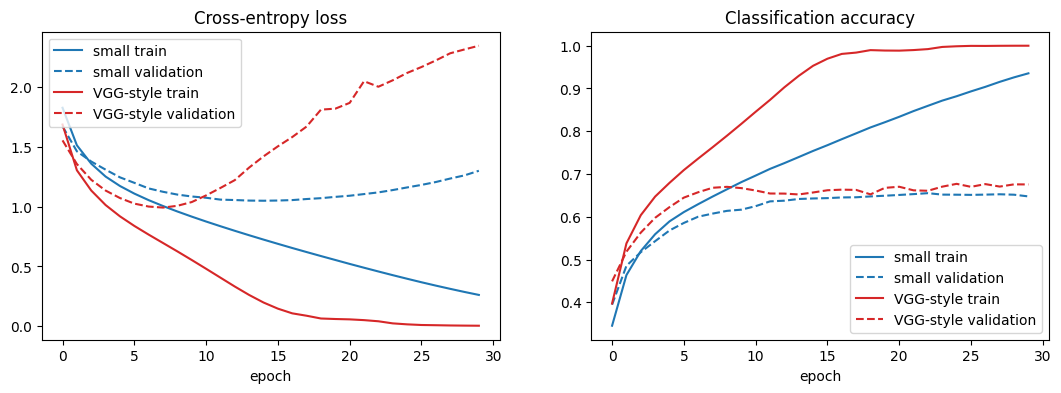

In [10]:
# Compare both models: does the deeper model perform better? Look at the gap between train and validation.
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4))
for history, name, color in ((history_small, "small", "tab:blue"), (history_vgg, "VGG-style", "tab:red")):
    ax_loss.plot(history.history["loss"], color=color, label=f"{name} train")
    ax_loss.plot(history.history["val_loss"], color=color, linestyle="--", label=f"{name} validation")
    ax_acc.plot(history.history["accuracy"], color=color, label=f"{name} train")
    ax_acc.plot(history.history["val_accuracy"], color=color, linestyle="--", label=f"{name} validation")
ax_loss.set_title("Cross-entropy loss")
ax_acc.set_title("Classification accuracy")
for ax in (ax_loss, ax_acc):
    ax.set_xlabel("epoch")
    ax.legend()
plt.show()

### 8.1c Transfer learning: InceptionV3 pre-trained on ImageNet

Instead of training from scratch, we reuse the knowledge of InceptionV3 trained on ImageNet:

* the base model is created **without its top** (`include_top=False`), so it ends with feature maps instead of the 1000 ImageNet classes;
* we add a **global average pooling** layer, a **dense layer of 1024 units** (our `features`) and the **classification layer**;
* **phase 1**: the base is **frozen** (`trainable = False`) and only the new layers are trained;
* **phase 2**: the base is unfrozen and the whole network is fine-tuned with a **very low learning rate**, so the pre-trained weights change only a little.

Design choices:

* InceptionV3 needs inputs of at least 75 × 75 px. The model keeps a **32 × 32 input** and a `Resizing` layer upsamples it to 128 × 128 inside the network. The passport therefore says "32 × 32", like the other models, and a photo seen by the app is first reduced to the CIFAR resolution the model was trained on.
* InceptionV3 expects pixels in **[-1, 1]** (`keras.applications.inception_v3.preprocess_input`): scale 1/127.5, offset -1.
* The **batch-normalisation layers stay frozen** during fine-tuning, so they keep the ImageNet statistics. Calling the base with `training=False` is not enough: once `base_model.trainable = True`, Keras 3 runs them in training mode during `fit`. They would then normalise with the statistics of each batch of 32 upsampled CIFAR images and overwrite the ImageNet averages, which changes the features the new head was trained on (in an earlier run the training accuracy fell from 89% to 51% in the first fine-tuning epoch and the validation accuracy from 73% to 67%).
* To keep training at about 10 minutes, a balanced subset of the training images is used. Increase `TRANSFER_TRAIN_SAMPLES` up to 50000 for a better model.

In [11]:
TRANSFER_SIZE = 128  # InceptionV3 needs at least 75 x 75 px: the model upsamples the 32 x 32 images itself
TRANSFER_TRAIN_SAMPLES = 10000  # balanced subset; 50000 uses the whole training set (slower, more accurate)
HEAD_EPOCHS = 5  # phase 1: frozen base, train the new layers
FINE_TUNE_EPOCHS = 3  # phase 2: fine-tune everything with a very low learning rate

inception_preprocessing = make_preprocessing(
    1 / 127.5, -1.0, "pixels scaled to [-1, 1] (inception_v3.preprocess_input); the model resizes 32 -> 128 px itself"
)

# Balanced subset: the same number of training images of every class, in random order
rng = np.random.default_rng(0)
per_class = TRANSFER_TRAIN_SAMPLES // len(CLASS_NAMES)
subset = np.concatenate([rng.choice(np.flatnonzero(y_train == c), per_class, replace=False) for c in range(len(CLASS_NAMES))])
rng.shuffle(subset)
x_train_transfer = prepare_batch(x_train[subset], inception_preprocessing)
y_train_transfer = y_train_onehot[subset]

keras.backend.clear_session()
base_model = keras.applications.InceptionV3(include_top=False, weights="imagenet", input_shape=(TRANSFER_SIZE, TRANSFER_SIZE, 3))
base_model.trainable = False  # phase 1: keep the ImageNet weights fixed

inputs = keras.Input(shape=(32, 32, 3))
x = layers.Resizing(TRANSFER_SIZE, TRANSFER_SIZE, interpolation="bilinear", name="upsample")(inputs)
x = base_model(x, training=False)  # inference mode while the base is frozen (phase 2 also freezes the batch-norm layers)
x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
x = layers.Dense(1024, activation="relu", name="features")(x)
x = layers.Dense(10, name="logits")(x)
outputs = layers.Activation("softmax", name="predictions")(x)
transfer_model = keras.Model(inputs, outputs, name="inceptionv3_transfer")
transfer_model.summary(show_trainable=True)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "inceptionv3_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 32, 32, 3)     │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ upsample (Resizing)         │ (None, 128, 128, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ inception_v3 (Functional)   │ (None, 2, 2, 2048)    │ 21,802,784 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_avg_pool             │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ features (Dense)            │ (None, 1024)          │  2,098,176 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ logits (Dense)              │ (None, 10)            │     10,250 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ predictions (Activation)    │ (None, 10)            │          0 │   -   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 23,911,210 (91.21 MB)

 Trainable params: 2,108,426 (8.04 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [12]:
start = time.perf_counter()

# Phase 1: only the new layers learn
transfer_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
history_head = transfer_model.fit(x_train_transfer, y_train_transfer, epochs=HEAD_EPOCHS, batch_size=32, validation_split=VALIDATION_SPLIT)

# Phase 2: unfreeze InceptionV3 and fine-tune the whole network (compile again after changing `trainable`)
base_model.trainable = True
for layer in base_model.layers:
    # Keep the ImageNet statistics: with trainable=True, Keras 3 runs batch-norm in training mode during fit
    # (despite training=False above), which overwrites the statistics and breaks the features the head learnt
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
transfer_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
history_fine = transfer_model.fit(x_train_transfer, y_train_transfer, epochs=FINE_TUNE_EPOCHS, batch_size=32, validation_split=VALIDATION_SPLIT)
transfer_seconds = time.perf_counter() - start

n_validation_transfer = int(len(x_train_transfer) * VALIDATION_SPLIT)
save_model_with_passport(
    transfer_model,
    name="inceptionv3_transfer",
    title="InceptionV3 transfer learning",
    description="InceptionV3 pre-trained on ImageNet: frozen base + new head, then fine-tuned with a low learning rate.",
    architecture=(
        f"Resizing 32 -> {TRANSFER_SIZE} -> InceptionV3 (ImageNet, no top) -> GlobalAveragePooling "
        "-> Dense 1024 ReLU (features) -> Dense 10 (logits) -> softmax"
    ),
    gradcam_layer=base_model.name,  # the whole InceptionV3 base: its output is the last feature maps
    preprocessing=inception_preprocessing,
    training={
        "optimizer": "Adam (1e-3 frozen base, then 1e-5 fine-tuning)",
        "loss": "categorical_crossentropy",
        "epochs": HEAD_EPOCHS + FINE_TUNE_EPOCHS,
        "batch_size": 32,
        "validation_split": VALIDATION_SPLIT,
        "seconds": round(transfer_seconds, 1),
        "phases": [
            {"name": "frozen InceptionV3, train the new layers", "epochs": HEAD_EPOCHS, "learning_rate": 1e-3},
            {"name": "fine-tune the whole network", "epochs": FINE_TUNE_EPOCHS, "learning_rate": 1e-5},
        ],
    },
    histories=[history_head, history_fine],
    train_samples=len(x_train_transfer) - n_validation_transfer,
    validation_samples=n_validation_transfer,
)

Epoch 1/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 78s 149ms/step - accuracy: 0.6837 - loss: 1.1771 - val_accuracy: 0.7010 - val_loss: 0.8692
Epoch 2/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 18s 26ms/step - accuracy: 0.7973 - loss: 0.6005 - val_accuracy: 0.6970 - val_loss: 0.9586
Epoch 3/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.8503 - loss: 0.4477 - val_accuracy: 0.7040 - val_loss: 0.9910
Epoch 4/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.8794 - loss: 0.3597 - val_accuracy: 0.7350 - val_loss: 0.8721
Epoch 5/5
282/282 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.8896 - loss: 0.3162 - val_accuracy: 0.7030 - val_loss: 1.0965
Epoch 1/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 155s 288ms/step - accuracy: 0.8998 - loss: 0.2869 - val_accuracy: 0.8030 - val_loss: 0.6471
Epoch 2/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 23s 82ms/step - accuracy: 0.9806 - loss: 0.0693 - val_accuracy: 0.8110 - val_loss: 0.7372
Epoch 3/3
282/282 ━━━━━━━━━━━━━━━━━━━━ 23s 80ms/step - accuracy: 0.9961 - loss: 0.0221 - val_accu

PosixPath('cnn_models/inceptionv3_transfer')

## 8.2 Load a pretrained model and use it

This is what the app does: read the passport, load the network, apply the passport's preprocessing to an image and read the class names from the passport.

In [13]:
def load_model_with_passport(folder):
    # Set 8.2: the trained network and its passport
    folder = Path(folder)
    passport = json.loads((folder / "passport.json").read_text())
    assert passport["format_version"] == PASSPORT_VERSION, "unknown passport version"
    model = keras.models.load_model(folder / passport["files"]["model"], compile=False)  # inference only
    return model, passport


def show_passport(passport):
    # Print the passport and plot its training history
    dataset, training, evaluation = passport["dataset"], passport["training"], passport["evaluation"]
    print(f"{passport['title']}  ({passport['name']}, created {passport['created']})")
    print(f"  architecture: {passport['architecture']['summary']} ({passport['architecture']['parameters']:,} parameters)")
    print(f"  dataset: {dataset['name']}: train {dataset['train_samples']:,}, "
          f"validation {dataset['validation_samples']:,}, test {dataset['test_samples']:,}")
    print("  classes:", ", ".join(passport["class_names"]))
    print("  preprocessing:", passport["preprocessing"])
    print(f"  training: {training['optimizer']}, {training['loss']}, {training['epochs']} epochs, batch {training['batch_size']}")
    print(f"  test accuracy {evaluation['test_accuracy']:.1%}, test loss {evaluation['test_loss']:.3f}")
    history = passport["history"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    for ax, metric in zip(axes, ("loss", "accuracy")):
        ax.plot(history[metric], label="train")
        ax.plot(history[f"val_{metric}"], label="validation")
        ax.set_title(metric)
        ax.set_xlabel("epoch")
        ax.legend()
    plt.show()


def classify_image(model, passport, image, top=3):
    # The `top` most likely classes of a PIL image, with their probabilities
    probabilities = model.predict(prepare_image(image, passport["preprocessing"]), verbose=0)[0]
    order = probabilities.argsort()[::-1][:top]
    return [(passport["class_names"][i], float(probabilities[i])) for i in order]

VGG-style CNN (2 conv layers)  (vgg_cnn, created 2026-11-23T22:50:11+00:00)
  architecture: 2 x Conv2D 32 3x3 ReLU (same) -> MaxPool 2x2 -> Flatten -> Dense 128 ReLU (features) -> Dense 10 (logits) -> softmax (1,060,138 parameters)
  dataset: CIFAR-10: train 45,000, validation 5,000, test 10,000
  classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck
  preprocessing: {'input_size': [32, 32], 'color_mode': 'rgb', 'resize_mode': 'center_crop', 'interpolation': 'bilinear', 'scale': 0.00392156862745098, 'offset': 0.0, 'description': 'pixels scaled to [0, 1]'}
  training: SGD (learning rate 0.01), categorical_crossentropy, 30 epochs, batch 32
  test accuracy 66.7%, test loss 2.431


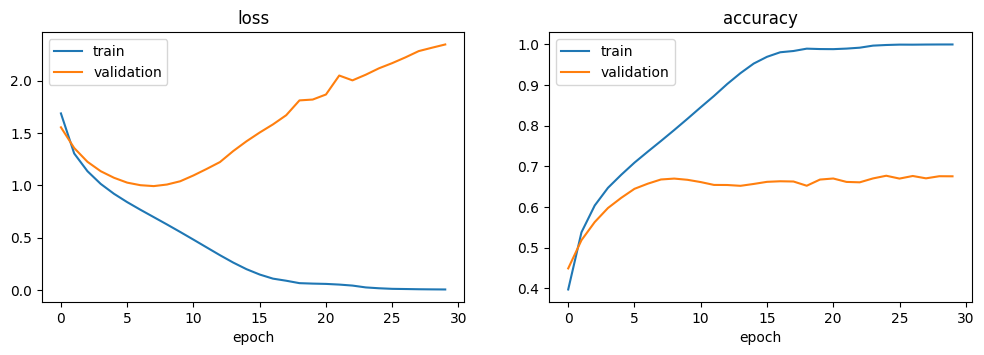

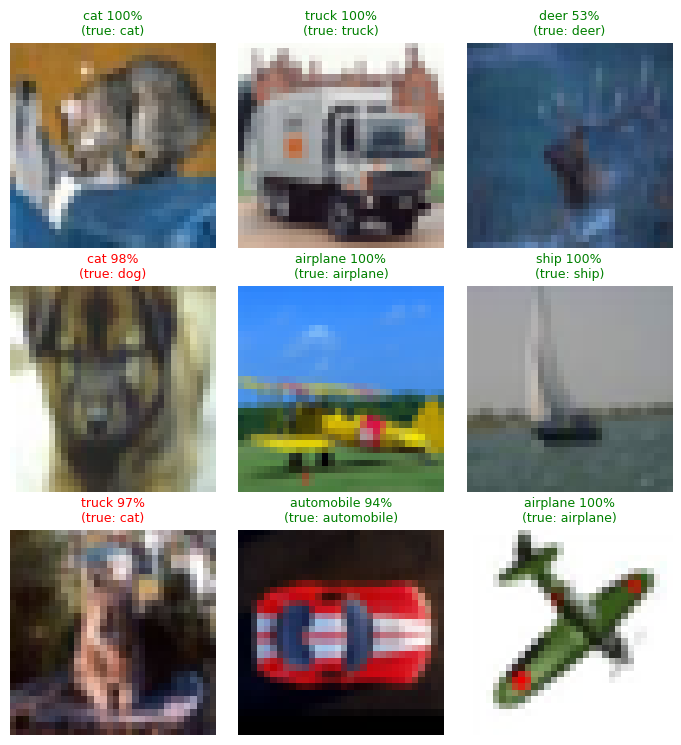

In [14]:
model, passport = load_model_with_passport(OUTPUT_DIR / "vgg_cnn")
show_passport(passport)

# Classify 9 of the saved test images: green = correct, red = wrong
samples = sorted((OUTPUT_DIR / "vgg_cnn" / "test_samples").glob("*.png"))[::11][:9]
fig, axes = plt.subplots(3, 3, figsize=(7, 7.5))
for ax, path in zip(axes.ravel(), samples):
    image = Image.open(path)
    (name, probability), *_ = classify_image(model, passport, image)
    true_name = path.stem.split("_", 1)[1]
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(f"{name} {probability:.0%}\n(true: {true_name})", color="green" if name == true_name else "red", fontsize=9)
plt.tight_layout()
plt.show()

### Grad-CAM: where did the network look?

Grad-CAM (Selvaraju et al., 2017) shows which part of the image made the network choose a class:

1. take the feature maps $A^k$ of the last layer with feature maps (`gradcam_layer` in the passport);
2. compute the gradients of the class score $y^c$ (the logit, before the softmax) with respect to them;
3. weight each map by the mean of its gradients, $\alpha_k = \text{mean}(\partial y^c / \partial A^k)$, and add them up;
4. keep the positive part (ReLU, evidence *for* the class) and scale it to [0, 1].

The app computes it the same way (*CNN: Classify Image*, "Show Grad-CAM"). The map has the resolution of that layer: 30 × 30 for the small CNN, 32 × 32 for the VGG-style CNN, and only about 2 × 2 for InceptionV3 at 128 × 128 px.

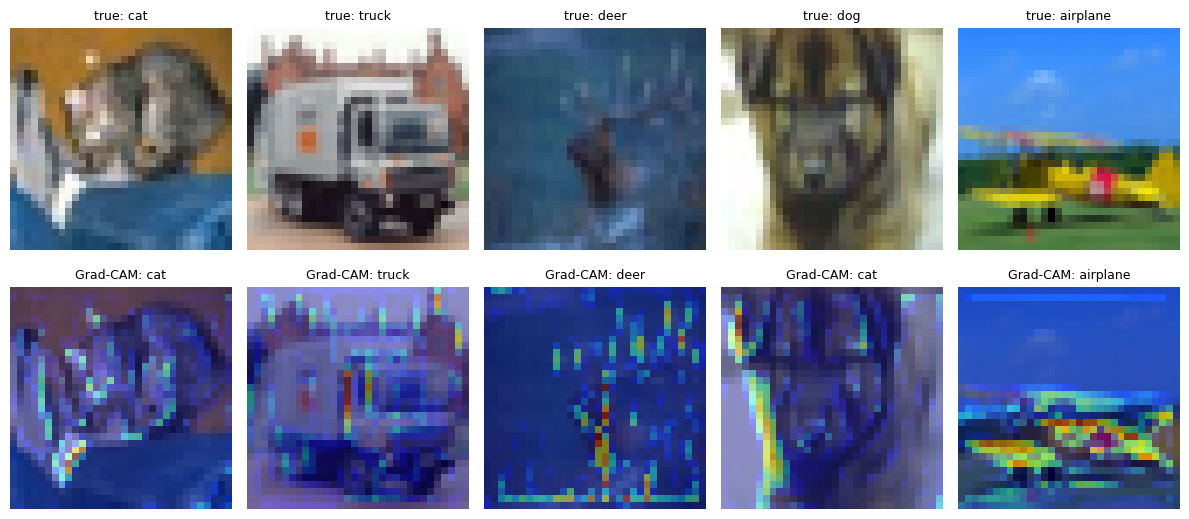

In [15]:
def gradcam(model, passport, image, class_index=None):
    # Grad-CAM heatmap (values 0..1, at the resolution of the layer) and the explained class.
    # The layers are called one by one inside the tape (the Set 8 models are simple chains),
    # so the tape records the path from the feature maps to the class score.
    target = passport["architecture"]["gradcam_layer"]
    x = tf.convert_to_tensor(prepare_image(image, passport["preprocessing"]))
    maps = logits = None
    with tf.GradientTape() as tape:
        for layer in model.layers:
            if isinstance(layer, keras.layers.InputLayer):
                continue
            x = layer(x)
            if layer.name == target:
                maps = x
                tape.watch(maps)  # we want d(score) / d(maps)
            if layer.name == "logits":
                logits = x  # class scores before the softmax
        if class_index is None:
            class_index = int(tf.argmax(logits[0]))  # explain the predicted class
        score = logits[:, class_index]
    gradients = tape.gradient(score, maps)[0].numpy()
    weights = gradients.mean(axis=(0, 1))  # alpha_k
    heatmap = np.maximum(maps[0].numpy() @ weights, 0)  # sum_k alpha_k A^k, then ReLU
    return (heatmap / heatmap.max() if heatmap.max() > 0 else heatmap), class_index


fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for column, path in enumerate(samples[:5]):
    image = Image.open(path)
    heatmap, class_index = gradcam(model, passport, image)
    smooth = np.asarray(Image.fromarray(heatmap.astype("float32")).resize(image.size, Image.Resampling.BILINEAR))
    axes[0, column].imshow(image)
    axes[0, column].set_title(f"true: {path.stem.split('_', 1)[1]}", fontsize=9)
    axes[1, column].imshow(image)
    axes[1, column].imshow(smooth, cmap="jet", alpha=0.45)
    axes[1, column].set_title(f"Grad-CAM: {passport['class_names'][class_index]}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [16]:
# Optional: classify your own photo (in Colab a file chooser opens)
try:
    from google.colab import files

    for filename in files.upload():
        image = Image.open(filename)
        plt.imshow(image)
        plt.axis("off")
        plt.title(", ".join(f"{name} {p:.0%}" for name, p in classify_image(model, passport, image)))
        plt.show()
except ImportError:
    print("Not in Colab: use classify_image(model, passport, Image.open(path)).")

## 8.3 Feature projection (t-SNE, UMAP)

1. **Extract** the feature vector of every test image (the output of the `features` layer) and **save** it with the true labels and the network's predictions, for easy loading.
2. **Load** the saved feature vectors.
3. **Project** them onto 2-D with **t-SNE** and **UMAP**. Both keep close in 2-D the images that are close in feature space. As usual, the features are first reduced to 50 dimensions with PCA (less noise, much faster t-SNE). The app uses the same recipe and the same random subset of 2000 test images.
4. **Visualise** them, one colour per class: well-separated clusters mean the features distinguish those classes.

In [17]:
def save_test_features(folder):
    # Feature vectors of the whole test set from the 'features' layer, saved as test_features.npz
    model, passport = load_model_with_passport(folder)
    extractor = keras.Model(model.inputs, model.get_layer("features").output)
    x = prepare_batch(x_test, passport["preprocessing"])
    features = extractor.predict(x, batch_size=256, verbose=0)
    predictions = model.predict(x, batch_size=256, verbose=0).argmax(axis=1)
    np.savez_compressed(
        Path(folder) / passport["files"]["test_features"],
        features=features.astype("float32"),
        labels=y_test.astype("int64"),
        predictions=predictions.astype("int64"),
    )
    print(f"{passport['name']}: saved {features.shape[0]} feature vectors of {features.shape[1]} values")


for folder in sorted(OUTPUT_DIR.iterdir()):
    save_test_features(folder)

inceptionv3_transfer: saved 10000 feature vectors of 1024 values
small_cnn: saved 10000 feature vectors of 100 values
vgg_cnn: saved 10000 feature vectors of 128 values


In [18]:
%pip install -q umap-learn

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


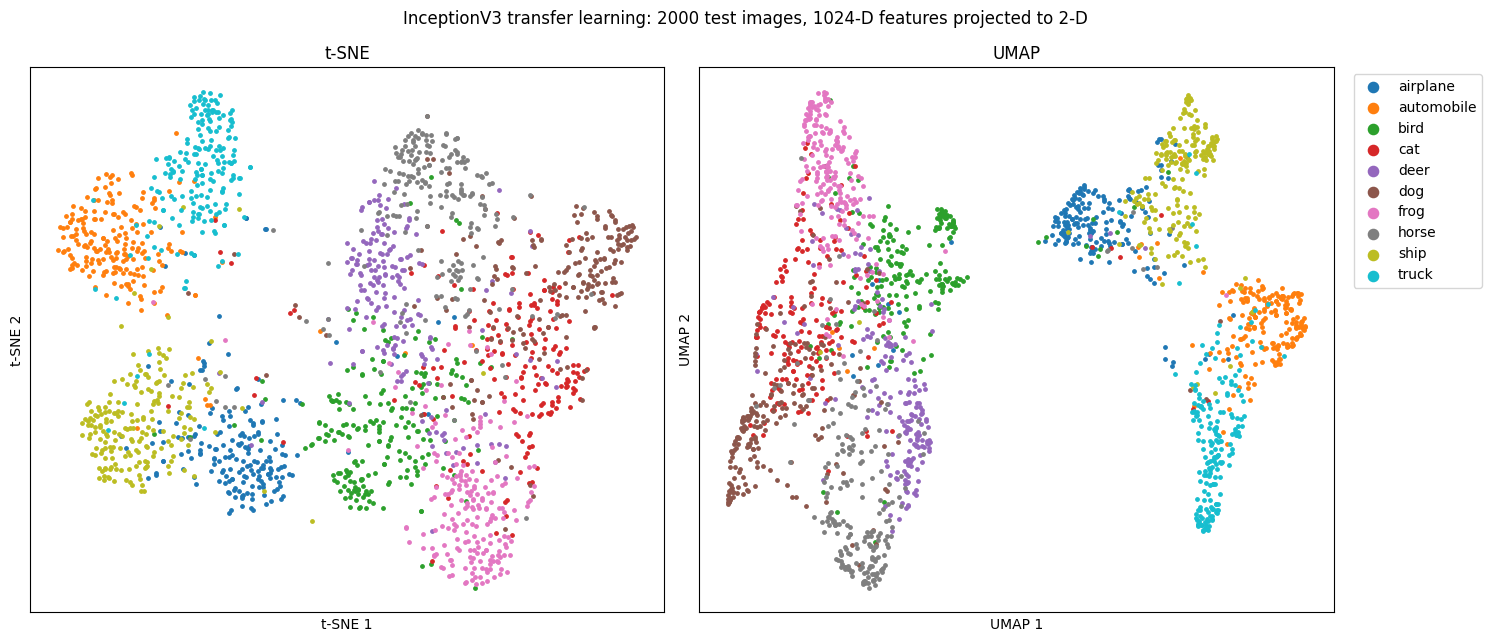

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


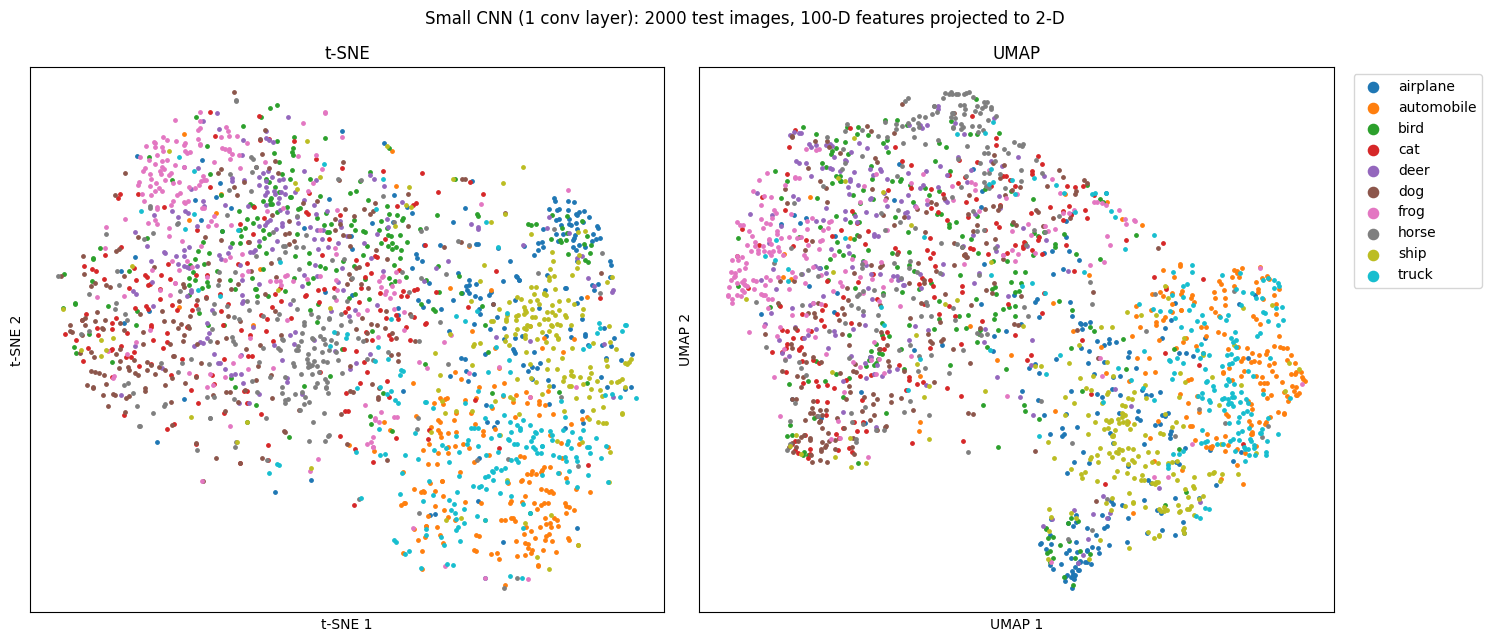

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


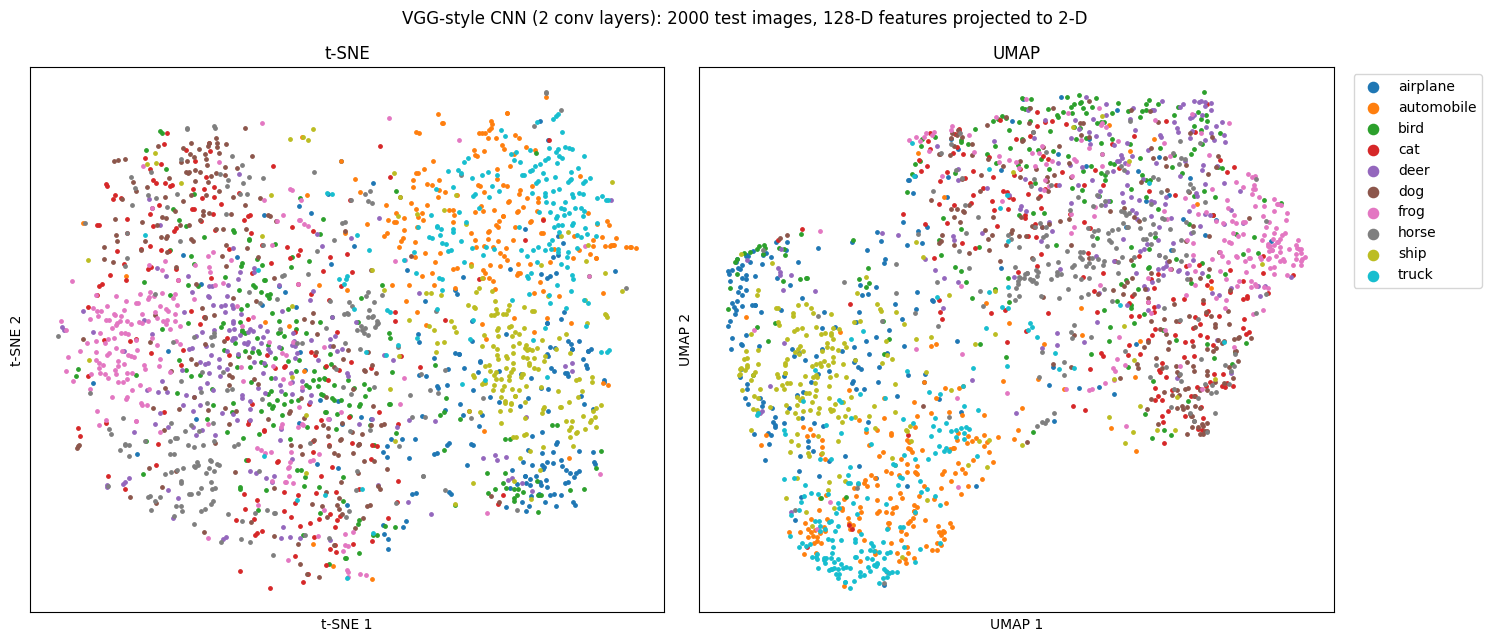

In [19]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

PROJECTION_POINTS = 2000  # random subset of the test set (t-SNE is slow with many points)


def load_test_features(folder):
    # The saved feature vectors, labels and predictions of one model
    passport = json.loads((Path(folder) / "passport.json").read_text())
    with np.load(Path(folder) / passport["files"]["test_features"]) as data:
        return passport, data["features"], data["labels"], data["predictions"]


def project_features(features, seed=0):
    # PCA to 50 dimensions, then t-SNE and UMAP to 2-D (same recipe as the app)
    reduced = PCA(n_components=50, random_state=0).fit_transform(features) if features.shape[1] > 50 else features
    tsne_points = TSNE(n_components=2, perplexity=30, init="pca", random_state=seed).fit_transform(reduced)
    umap_points = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=seed).fit_transform(reduced)
    return tsne_points, umap_points


def plot_projections(folder):
    passport, features, labels, predictions = load_test_features(folder)
    keep = np.sort(np.random.default_rng(0).choice(len(labels), PROJECTION_POINTS, replace=False))
    tsne_points, umap_points = project_features(features[keep])
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
    for ax, points, method in ((axes[0], tsne_points, "t-SNE"), (axes[1], umap_points, "UMAP")):
        for label, name in enumerate(passport["class_names"]):
            mask = labels[keep] == label
            ax.scatter(points[mask, 0], points[mask, 1], s=6, color=plt.cm.tab10(label), label=name)
        ax.set_title(method)
        ax.set_xlabel(f"{method} 1")
        ax.set_ylabel(f"{method} 2")
        ax.set_xticks([])
        ax.set_yticks([])
    axes[1].legend(markerscale=3, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle(f"{passport['title']}: {PROJECTION_POINTS} test images, {features.shape[1]}-D features projected to 2-D")
    plt.tight_layout()
    plt.show()


for folder in sorted(OUTPUT_DIR.iterdir()):
    plot_projections(folder)

## Download the models for ForensicsApp

Unzip `cnn_models.zip` into `ForensicsApp/models/cnn/`. Every model must end up in its own folder, e.g. `models/cnn/vgg_cnn/passport.json`.

In [20]:
archive = shutil.make_archive("cnn_models", "zip", root_dir=OUTPUT_DIR)
print("Created", archive, "- unzip it into ForensicsApp/models/cnn/")
try:
    from google.colab import files

    files.download(archive)
except ImportError:
    pass

Created /content/cnn_models.zip - unzip it into ForensicsApp/models/cnn/


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Questions from the lab

* What is the use of activation functions in a network? Why are they needed?
* What is the difference between the sigmoid and the softmax activation?
* What is the difference between the categorical and the binary cross-entropy loss?
* When do we train models from scratch? What are the potential issues?
* Why do we use pre-trained weights? What is the difference between random initialisation and pre-trained weights?
* Why is feature visualisation helpful? Compare the t-SNE / UMAP plots of the three models: which classes overlap, and does it match the confusion matrices?